# 01 | UNSW-NB15 Dataset Inspection
**Author: Samar** · written for Google Colab (reads data from the team's shared Drive folder)

AI/ML team · BRR CyberShield AI · Phase 1 (tasks AI-002, AI-003)

## 1. Connect Google Drive
All project files live in one shared Drive folder, so the data is downloaded once and the whole team works from the same place.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
PROJECT = '/content/drive/MyDrive/BRR_CyberShield_AI'
DATA_DIR = f'{PROJECT}/data/unsw_nb15'
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(f'{PROJECT}/notebooks', exist_ok=True)

print('Project folder:', PROJECT)
print('Contents:', os.listdir(PROJECT))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project folder: /content/drive/MyDrive/BRR_CyberShield_AI
Contents: ['data', 'notebooks']


## 2. Get the official dataset (once) and verify it
Downloads the two official UNSW-NB15 files into the Drive folder only if they are not there yet, then checks each file's SHA-256 fingerprint against the files BRR supplied.

In [ ]:
import hashlib, urllib.request

MIRROR = 'https://huggingface.co/datasets/Mireu-Lab/UNSW-NB15/resolve/main/'
FILES = {
    'UNSW_NB15_training-set.csv': ('test.csv', 'bec7dd5ec88dc2a0ccc7a07879d338395ed7421750f675fd0339e07dfe0648fa'),
    'UNSW_NB15_testing-set.csv':  ('train.csv', '734fe6642edf758f7c94d7d9149426b49d202fe8e7bf0bef47392489c3c0a559'),
}

for official_name, (mirror_name, expected) in FILES.items():
  path = f'{DATA_DIR}/{official_name}'
  if not os.path.exists(path):
    print('Downloading', official_name, '...')
    urllib.request.urlretrieve(MIRROR + mirror_name + path)
  sha = hashlib.sha256(open(path, 'rb').read()).hexdigest()
  status = 'OK' if sha == expected else 'HASH MISMATCH!'
  print(f'{official_name}: {status} ({os.path.getsize(path)/1e6:.1f} MB)')

UNSW_NB15_training-set.csv: OK (32.3 MB)
UNSW_NB15_testing-set.csv: OK (15.4 MB)


## 3. Load the data and take a first look

In [ ]:
import pandas as pd
train = pd.read_csv(f'{DATA_DIR}/UNSW_NB15_training-set.csv')
test = pd.read_csv(f'{DATA_DIR}/UNSW_NB15_testing-set.csv')

print('Training set:', train.shape)
print('Testing set:', test.shape)
train.head()

Training set: (175341, 45)
Testing set: (82332, 45)


,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.121478,tcp,-,FIN,6,4,258,172,74.087490,...,1,1,0,0,0,1,1,0,Normal,0
1,2,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,...,1,2,0,0,0,1,6,0,Normal,0
2,3,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,...,1,3,0,0,0,2,6,0,Normal,0
3,4,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,...,1,3,1,1,0,2,1,0,Normal,0
4,5,0.449454,tcp,-,FIN,10,6,534,268,33.373826,...,1,40,0,0,0,2,39,0,Normal,0


## 4. Class balance
How many normal vs attack rows does each file have, and which attack families are there?

In [ ]:
print('--- label (training) ---')
print(train['label'].value_counts())

print('---attack_cat (training) ---')
print(train['attack_cat'].value_counts())

--- label (training) ---
label
1    119341
0     56000
Name: count, dtype: int64
---attack_cat (training) ---
attack_cat
Normal            56000
Generic           40000
Exploits          33393
Fuzzers           18184
DoS               12264
Reconnaissance    10491
Analysis           2000
Backdoor           1746
Shellcode          1133
Worms               130
Name: count, dtype: int64


## 5. Is `label` just a summary of `attack_cat`?
A cross-tabulation counts every combination of the two columns.

In [ ]:
pd.crosstab(train['attack_cat'], train['label'])

label,0,1
attack_cat,,
Analysis,0,2000
Backdoor,0,1746
DoS,0,12264
Exploits,0,33393
Fuzzers,0,18184
Generic,0,40000
Normal,56000,0
Reconnaissance,0,10491
Shellcode,0,1133


## 6. Is the file ordered?
Check where the first non-normal row appears.

In [ ]:
first_attack = train[train['label'] == 1].index[0]
print('First attack row is at position:', first_attack)
print('Labels of rows 0-9:', train['label'].head(10).tolist())

First attack row is at position: 47911
Labels of rows 0-9: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


## 7. Column types
Which columns are numbers and which are text (categories)?

In [ ]:
print(train.dtypes.value_counts())
print()
text_cols = train.select_dtypes(include = 'object').columns.tolist()
print('Text columns:', text_cols)

int64      30
float64    11
object      4
Name: count, dtype: int64

Text columns: ['proto', 'service', 'state', 'attack_cat']


## 8. Missing values
Real missing values (empty cells) and hidden ones: UNSW uses '-' to mean "unknown".

In [ ]:
print('EMPTY cells in the whole training set:', train.isna().sum().sum())
print()
for col in text_cols:
  dash = (train[col] == '-').sum()
  print(f'{col}: {dash:,} rows with "-" ({dash/len(train):.1%})')

EMPTY cells in the whole training set: 0

proto: 0 rows with "-" (0.0%)
service: 94,168 rows with "-" (53.7%)
state: 0 rows with "-" (0.0%)
attack_cat: 0 rows with "-" (0.0%)


## 9. Duplicate rows
Rows that are exact copies of another row (ignoring the `id` column, which is always unique).

In [ ]:
dups = train.drop(columns='id').duplicated().sum()
print(f'Exact duplicate rows: {dups:,} ({dups / len(train):.1%} of the training set)')

Exact duplicate rows: 67,601 (38.6% of the training set)


## 10. Numeric columns: typical vs extreme values
For each numeric column: the median (typical value), the maximum, and the share of zeros.

In [ ]:
num_cols = [c for c in train.select_dtypes(include='number').columns if c not in ['id', 'label']]
summary = pd.DataFrame({
    'median': train[num_cols].median(),
    'max': train[num_cols].max(),
    'zeros_%': (train[num_cols] == 0).mean() * 100,
     }).round(2)
print('Numeric feature columns:', len(num_cols))
summary.sort_values('max', ascending=False).head(15)

Numeric feature columns: 39


,median,max,zeros_%
sload,879674.75,5.988000e+09,1.70
stcpb,0.00,4.294959e+09,54.89
dtcpb,0.00,4.294882e+09,54.89
dload,1447.02,2.242273e+07,48.07
dbytes,164.00,1.465555e+07,48.07
sbytes,430.00,1.296523e+07,0.00
response_body_len,0.00,6.558056e+06,93.56
sjit,0.00,1.460480e+06,50.47
rate,3225.81,1.000000e+06,1.69
djit,0.00,2.893883e+05,53.46


## 11. Do attacks look different from normal traffic?
Histograms of two features for each class, on a log scale.

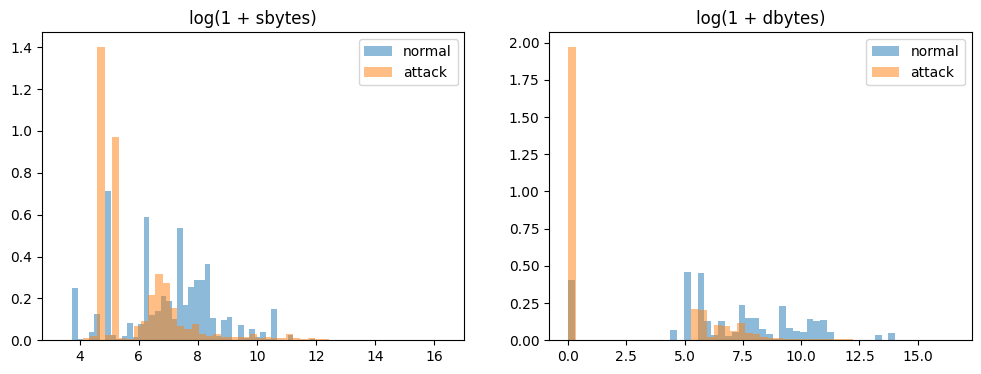

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12,4))
for ax, col in zip(axes, ['sbytes', 'dbytes']):
  for value, name in [(0, 'normal'), (1, 'attack')]:
    data = np.log1p(train.loc[train['label'] == value, col])
    ax.hist(data, bins=50, alpha=0.5, density=True, label=name)
  ax.set_title(f'log(1 + {col})')
  ax.legend()

plt.show()

## 12. Categorical columns: how many values, and which are most common?

In [ ]:
for col in ['proto', 'service', 'state']:
  print(f'--- {col}: {train[col].nunique()} different values ---')
  print(train[col].value_counts().head(5))
  print()

--- proto: 133 different values ---
proto
tcp     79946
udp     63283
unas    12084
arp      2859
ospf     2595
Name: count, dtype: int64

--- service: 13 different values ---
service
-           94168
dns         47294
http        18724
smtp         5058
ftp-data     3995
Name: count, dtype: int64

--- state: 9 different values ---
state
INT    82275
FIN    77825
CON    13152
REQ     1991
RST       83
Name: count, dtype: int64



## 13. Attack rate per category
For each value of `state`: what share of its rows are attacks?

In [ ]:
train.groupby('state')['label'].agg(['count', 'mean']).sort_values('count', ascending=False)

,count,mean
state,,
INT,82275,0.930538
FIN,77825,0.522326
CON,13152,0.080064
REQ,1991,0.535409
RST,83,0.144578
ECO,12,0.000000
PAR,1,0.000000
URN,1,0.000000
no,1,0.000000


## 14. Values the model will see for the first time
Categories that appear in the testing set but never in the training set.

In [ ]:
for col in ['proto', 'service', 'state']:
  new_values = set(test[col]) - set(train[col])
  print(f'{col}: {sorted(new_values) if new_values else "none"}')

proto: none
service: none
state: ['ACC', 'CLO']


# UNSW-NB15: what we found in the data

**AI/ML team · Week 1 · Tasks AI-002 (done) and AI-003 (in progress)**

I went through the official dataset to understand what we're working with before we start building anything. These are the main findings. The cell numbers point to the code, if you want to see how each result was produced.

---

## 1. The data is the right data  *(cells 2–3)*

Both files match the ones BRR sent us exactly (checked by SHA-256 fingerprint), and the row counts match the official numbers.

| | Training | Testing |
|---|---:|---:|
| Rows | 175,341 | 82,332 |
| Columns | 45 | 45 |

## 2. The answer columns  *(cells 4–5)*

- `label` is the answer we want to predict: **0 = normal, 1 = attack**.
- `attack_cat` names the attack type (9 families + Normal), so `label` can be worked out from it directly.
- That means **`id`, `label` and `attack_cat` stay out of the model's inputs**. Giving them to the model would be handing it the answer (target leakage).

## 3. Things we need to be careful with  *(cells 4, 6, 8, 9)*

| What we noticed | The numbers | What it means for us |
|---|---|---|
| More attacks than normal traffic | 119,341 attacks vs 56,000 normal (68% attacks) | The data comes from a lab. On a real network the model will probably raise too many false alarms. |
| The file is sorted | The first 47,911 rows are all normal | Always shuffle (and keep the same normal/attack ratio) before splitting the data. |
| Hidden "unknown" values | No empty cells, but `service` is "-" in 94,168 rows (53.7%) | Keep "-" as its own category instead of deleting half the data. |
| Repeated rows | 67,601 exact duplicates (38.6%) | Don't delete them blindly: train with and without them and compare. |

## 4. How attacks differ from normal traffic  *(cells 10–11)*

- Many attacks have `dbytes = 0`, meaning **the other side never replied**, like probing ports that are closed. Normal traffic is usually a two-way exchange.
- Most numeric columns have a small typical value and a few huge ones, so we look at them on a log scale.
- HTTP/FTP columns are almost always zero (`response_body_len` is 0 in about 93% of rows), because most connections aren't HTTP or FTP.

## 5. What will affect the next tasks  *(cells 10, 12–14)*

- `proto` has **133 different values**, but Zeek only reports **tcp, udp and icmp**. We'll need to group the rare ones.
- **93%** of `state = INT` rows are attacks. The model may learn "INT means attack", which is true in the lab but not necessarily on a real network.
- `stcpb` and `dtcpb` are random TCP sequence numbers. They don't describe behaviour, and Zeek doesn't provide them.
- The testing file has two `state` values the training file never has (`ACC`, `CLO`). Our preprocessing has to handle values it hasn't seen without breaking.

---

## Where we are

| Task | Status |
|---|---|
| AI-002: verify the dataset | Done |
| AI-003: inspect the dataset | In progress |
| AI-004: feature register (all 45 columns) | Next |
| AI-005: preprocessing pipeline | Next |

The notebook and the data are in the shared Drive folder **BRR_CyberShield_AI**, and every code cell has a short explanation above it.

In [ ]:
!python --version

Python 3.13.18
